<a href="https://colab.research.google.com/github/Hazem7774/tableau-de-bord-/blob/main/Copie_de_detectionFraudeCarteBancaire.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>





# Hazem Jannen

# **Introduction**

La fraude à la carte bancaire représente un défi majeur pour les institutions financières. Bien qu’elle constitue une faible proportion du volume total des transactions, son impact financier est considérable en raison des remboursements clients, des coûts opérationnels et des risques réglementaires. De plus, une détection inefficace peut nuire à la réputation de la banque et à la confiance des utilisateurs. Ainsi, la mise en place de modèles de Data Mining capables d’identifier rapidement les transactions suspectes au sein de millions d’opérations légitimes est devenue un enjeu stratégique pour le secteur bancaire et la Fintech.





In [ ]:
#  IMPORT DES LIBRAIRIES

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import joblib
import warnings
warnings.filterwarnings('ignore')

from sklearn.model_selection import train_test_split, RandomizedSearchCV, StratifiedKFold
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (classification_report, confusion_matrix,
                             roc_auc_score, roc_curve, auc,
                             precision_recall_curve, average_precision_score,
                             f1_score)
from imblearn.over_sampling import SMOTE
import xgboost as xgb

import tensorflow as tf
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Dense, Dropout
from tensorflow.keras.callbacks import EarlyStopping
from tensorflow.keras.utils import plot_model

In [ ]:
# Pour la reproductibilité
np.random.seed(42)
tf.random.set_seed(42)

Pour garantir la reproductibilité des expériences en apprentissage automatique, il est essentiel de contrôler les sources d’aléatoire. Les lignes que vous montrez initialisent les générateurs de nombres aléatoires de NumPy et de TensorFlow avec une graine (seed) fixe. Cela permet d’obtenir les mêmes résultats à chaque exécution, à condition que le reste de l’environnement soit identique.

In [ ]:
import kagglehub

# Download latest version
path = kagglehub.dataset_download("mlg-ulb/creditcardfraud")

print("Path to dataset files:", path)
import kagglehub

# Download latest version
path = kagglehub.dataset_download("mlg-ulb/creditcardfraud")

print("Path to dataset files:", path)

# 🔹 Load the dataset into a DataFrame
df = pd.read_csv(f"{path}/creditcard.csv")

Using Colab cache for faster access to the 'creditcardfraud' dataset.
Path to dataset files: /kaggle/input/creditcardfraud
Using Colab cache for faster access to the 'creditcardfraud' dataset.
Path to dataset files: /kaggle/input/creditcardfraud



ANALYSE EXPLORATOIRE


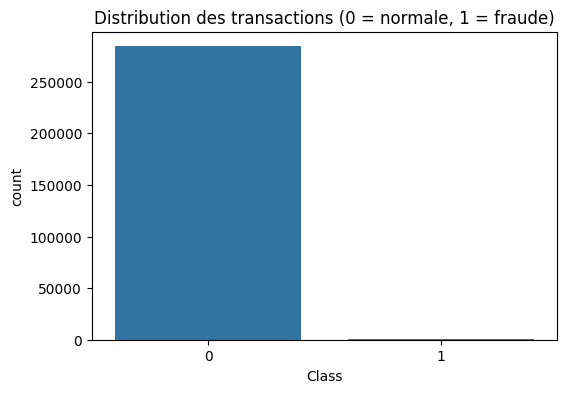

In [ ]:
#  ANALYSE EXPLORATOIRE (EDA)

print("\n" + "=" * 60)
print("ANALYSE EXPLORATOIRE")
print("=" * 60)

# Distribution des classes
plt.figure(figsize=(6,4))
sns.countplot(x='Class', data=df)
plt.title('Distribution des transactions (0 = normale, 1 = fraude)')
plt.savefig('distribution_classes.png')
plt.show()

# **Présentation du dataset**

Source : Kaggle – Credit Card Fraud Detection (Université Libre de Bruxelles)

Dimensions : 284 807 transactions, 31 variables

Variables principales :

Time : temps écoulé depuis la première transaction

Amount : montant de la transaction

V1 à V28 : composantes principales issues d’une ACP (anonymisation)

Class : variable cible (0 = normale, 1 = frauduleuse)

Déséquilibre marqué :

Transactions normales : 284 315 (99,83 %)

Transactions frauduleuses : 492 (0,17 %)


In [ ]:

# Statistiques sur le montant
print("\nStatistiques du montant par classe :")
print(df.groupby('Class')['Amount'].describe())



# Corrélations avec la cible
corr = df.corrwith(df['Class']).sort_values(ascending=False)
print("\nTop 10 des corrélations avec la classe :")
print(corr.head(10))


Statistiques du montant par classe :
          count        mean         std  min   25%    50%     75%       max
Class                                                                      
0      284315.0   88.291022  250.105092  0.0  5.65  22.00   77.05  25691.16
1         492.0  122.211321  256.683288  0.0  1.00   9.25  105.89   2125.87

Top 10 des corrélations avec la classe :
Class    1.000000
V11      0.154876
V4       0.133447
V2       0.091289
V21      0.040413
V19      0.034783
V20      0.020090
V8       0.019875
V27      0.017580
V28      0.009536
dtype: float64


Les transactions frauduleuses sont souvent de petits montants (médiane à 9,25 €) pour passer inaperçues.

Corrélations avec la cible : Les variables V4, V11, V2 sont les plus corrélées à la fraude.

In [ ]:
#  PRETRAITEMENT

print("\n" + "=" * 60)
print("PRETRAITEMENT")
print("=" * 60)

# Normalisation de Time et Amount
scaler = StandardScaler()
df['norm_Amount'] = scaler.fit_transform(df['Amount'].values.reshape(-1,1))
df['norm_Time'] = scaler.fit_transform(df['Time'].values.reshape(-1,1))
df.drop(['Amount', 'Time'], axis=1, inplace=True)

# Séparation features / cible
X = df.drop('Class', axis=1)
y = df['Class']

# Split entraînement / test (stratifié)
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, stratify=y, random_state=42
)

print(f"Taille entraînement : {X_train.shape[0]} échantillons")
print(f"Taille test : {X_test.shape[0]} échantillons")
print(f"Fraudes en entraînement : {y_train.sum()} / {len(y_train)} ({100*y_train.mean():.3f}%)")
print(f"Fraudes en test : {y_test.sum()} / {len(y_test)} ({100*y_test.mean():.3f}%)")


PRETRAITEMENT
Taille entraînement : 227845 échantillons
Taille test : 56962 échantillons
Fraudes en entraînement : 394 / 227845 (0.173%)
Fraudes en test : 98 / 56962 (0.172%)


Normalisation des variables Time et Amount (StandardScaler) pour les mettre à l’échelle des composantes PCA déjà centrées-réduites.

Division entraînement/test : 80 % / 20 % avec stratification pour conserver la proportion de fraudes.

In [ ]:
# Prévention du data leakage (si colonnes existent)
cols_to_drop = ['newbalanceOrig', 'newbalanceDest']
X_train.drop(columns=[c for c in cols_to_drop if c in X_train.columns], inplace=True)
X_test.drop(columns=[c for c in cols_to_drop if c in X_test.columns], inplace=True)


Si vous cherchez à prédire si une transaction est frauduleuse, le solde après la transaction donne une information quasi certaine sur le résultat : une fraude aboutit souvent à un solde très différent du solde avant.

Le modèle apprendrait alors à utiliser cette information post‑événement, ce qui le rendrait inutilisable en pratique, car au moment de la prédiction (avant validation de la transaction) on ne connaît pas encore le solde final.

En résumé, cette étape garantit que le modèle n’apprend pas à partir de données qui ne seraient pas disponibles en conditions réelles, et protège ainsi la fiabilité des performances mesurées sur l’ensemble de test.

In [ ]:
#  GESTION DU DESEQUILIBRE

print("\n" + "=" * 60)
print("GESTION DU DESEQUILIBRE")
print("=" * 60)

# Calcul du ratio pour la pondération XGBoost
ratio = (y_train == 0).sum() / (y_train == 1).sum()
print(f"Ratio (neg/pos) pour XGBoost : {ratio:.2f}")

# SMOTE pour les modèles qui en ont besoin
smote = SMOTE(random_state=42)
X_train_smote, y_train_smote = smote.fit_resample(X_train, y_train)
print(f"Après SMOTE : {X_train_smote.shape} - Répartition: {pd.Series(y_train_smote).value_counts().to_dict()}")


GESTION DU DESEQUILIBRE
Ratio (neg/pos) pour XGBoost : 577.29
Après SMOTE : (454902, 30) - Répartition: {0: 227451, 1: 227451}


SMOTE (Synthetic Minority Over-sampling Technique) :
Génère des exemples synthétiques de la classe minoritaire par interpolation entre voisins.
Utilisé pour la régression logistique et Random Forest.

Pondération des classes (scale_pos_weight) :
Pour XGBoost, on donne un poids plus élevé aux erreurs sur la classe minoritaire.
Ratio = nombre de normales / nombre de fraudes (calculé sur l’entraînement).

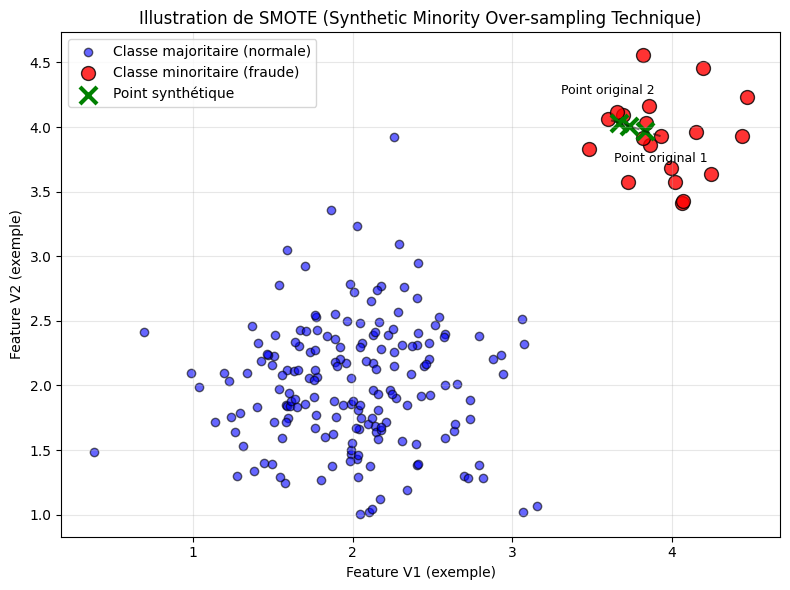

In [ ]:
# Générer des données factices pour illustration
from sklearn.datasets import make_blobs
np.random.seed(42)
n_samples = 200
# Classe majoritaire (0) : 180 points
X_major, y_major = make_blobs(n_samples=180, centers=[[2,2]], cluster_std=0.5, random_state=42)
# Classe minoritaire (1) : 20 points
X_minor, y_minor = make_blobs(n_samples=20, centers=[[4,4]], cluster_std=0.3, random_state=42)

X = np.vstack([X_major, X_minor])
y = np.hstack([np.zeros(180), np.ones(20)])

# Tracer les points originaux
plt.figure(figsize=(8,6))
plt.scatter(X[y==0][:,0], X[y==0][:,1], c='blue', label='Classe majoritaire (normale)', alpha=0.6, edgecolors='k')
plt.scatter(X[y==1][:,0], X[y==1][:,1], c='red', label='Classe minoritaire (fraude)', alpha=0.8, edgecolors='k', s=100)

# Choisir deux points de la classe minoritaire pour illustrer SMOTE
idx = np.where(y==1)[0]
p1 = X[idx[0]]
p2 = X[idx[5]]  # un autre point

# Tracer le segment entre eux
plt.plot([p1[0], p2[0]], [p1[1], p2[1]], 'k--', alpha=0.5)

# Générer 3 points synthétiques le long du segment
for i, alpha in enumerate([0.3, 0.6, 0.8]):
    synthetic = p1 + alpha * (p2 - p1)
    plt.scatter(synthetic[0], synthetic[1], c='green', marker='x', s=150, linewidths=3, label='Point synthétique' if i==0 else '')

# Annotations
plt.text(p1[0], p1[1]-0.2, 'Point original 1', fontsize=9, ha='center')
plt.text(p2[0], p2[1]+0.2, 'Point original 2', fontsize=9, ha='center')
plt.title('Illustration de SMOTE (Synthetic Minority Over-sampling Technique)')
plt.xlabel('Feature V1 (exemple)')
plt.ylabel('Feature V2 (exemple)')
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.savefig('smote_illustration.png', dpi=150)
plt.show()

In [ ]:
#  MODELISATION
# ================================
print("\n" + "=" * 60)
print("MODELISATION")
print("=" * 60)

results = {}

# ---  Régression Logistique ---
print("\n--- Régression Logistique (avec SMOTE) ---")
lr = LogisticRegression(max_iter=1000, random_state=42)
lr.fit(X_train_smote, y_train_smote)
y_pred_lr = lr.predict(X_test)
y_proba_lr = lr.predict_proba(X_test)[:, 1]
print(classification_report(y_test, y_pred_lr, digits=4))
print(f"AUC-ROC : {roc_auc_score(y_test, y_proba_lr):.4f}")
results['Logistic Regression'] = {
    'model': lr,
    'y_pred': y_pred_lr,
    'y_proba': y_proba_lr
}


MODELISATION

--- Régression Logistique (avec SMOTE) ---
              precision    recall  f1-score   support

           0     0.9999    0.9744    0.9869     56864
           1     0.0581    0.9184    0.1094        98

    accuracy                         0.9743     56962
   macro avg     0.5290    0.9464    0.5481     56962
weighted avg     0.9982    0.9743    0.9854     56962

AUC-ROC : 0.9698


In [ ]:
# ---  Random Forest ---
print("\n--- Random Forest (avec SMOTE) ---")
rf = RandomForestClassifier(n_estimators=100, random_state=42, n_jobs=-1)
rf.fit(X_train_smote, y_train_smote)
y_pred_rf = rf.predict(X_test)
y_proba_rf = rf.predict_proba(X_test)[:, 1]
print(classification_report(y_test, y_pred_rf, digits=4))
print(f"AUC-ROC : {roc_auc_score(y_test, y_proba_rf):.4f}")
results['Random Forest'] = {
    'model': rf,
    'y_pred': y_pred_rf,
    'y_proba': y_proba_rf
}


--- Random Forest (avec SMOTE) ---
              precision    recall  f1-score   support

           0     0.9997    0.9997    0.9997     56864
           1     0.8144    0.8061    0.8103        98

    accuracy                         0.9994     56962
   macro avg     0.9070    0.9029    0.9050     56962
weighted avg     0.9993    0.9994    0.9993     56962

AUC-ROC : 0.9688


it takes a long period to execute

In [ ]:
#  XGBoost (avec pondération) ---
print("\n--- XGBoost (scale_pos_weight) ---")
xgb_model = xgb.XGBClassifier(
    scale_pos_weight=ratio,
    use_label_encoder=False,
    eval_metric='logloss',
    random_state=42,
    n_jobs=-1
)
xgb_model.fit(X_train, y_train)  # pas de SMOTE
y_pred_xgb = xgb_model.predict(X_test)
y_proba_xgb = xgb_model.predict_proba(X_test)[:, 1]
print(classification_report(y_test, y_pred_xgb, digits=4))
print(f"AUC-ROC : {roc_auc_score(y_test, y_proba_xgb):.4f}")
results['XGBoost'] = {
    'model': xgb_model,
    'y_pred': y_pred_xgb,
    'y_proba': y_proba_xgb
}


--- XGBoost (scale_pos_weight) ---
              precision    recall  f1-score   support

           0     0.9997    0.9998    0.9998     56864
           1     0.8830    0.8469    0.8646        98

    accuracy                         0.9995     56962
   macro avg     0.9414    0.9234    0.9322     56962
weighted avg     0.9995    0.9995    0.9995     56962

AUC-ROC : 0.9652


In [ ]:
#  Réseau de neurones (avec pondération) ---
print("\n--- Réseau de neurones (class_weight) ---")
model_nn = Sequential([
    Dense(128, activation='relu', input_shape=(X_train.shape[1],)),
    Dropout(0.3),
    Dense(64, activation='relu'),
    Dropout(0.3),
    Dense(32, activation='relu'),
    Dense(1, activation='sigmoid')
])
model_nn.compile(optimizer='adam', loss='binary_crossentropy', metrics=['accuracy'])

class_weight = {0: 1., 1: ratio}
early_stop = EarlyStopping(monitor='val_loss', patience=5, restore_best_weights=True)

history = model_nn.fit(
    X_train, y_train,
    validation_split=0.2,
    epochs=50,
    batch_size=256,
    class_weight=class_weight,
    callbacks=[early_stop],
    verbose=0
)

y_pred_nn = (model_nn.predict(X_test) > 0.5).astype(int)
y_proba_nn = model_nn.predict(X_test).ravel()
print(classification_report(y_test, y_pred_nn, digits=4))
print(f"AUC-ROC : {roc_auc_score(y_test, y_proba_nn):.4f}")
results['Neural Network'] = {
    'model': model_nn,
    'y_pred': y_pred_nn,
    'y_proba': y_proba_nn
}



--- Réseau de neurones (class_weight) ---
1781/1781 ━━━━━━━━━━━━━━━━━━━━ 2s 1ms/step
1781/1781 ━━━━━━━━━━━━━━━━━━━━ 2s 1ms/step
              precision    recall  f1-score   support

           0     0.9998    0.9919    0.9958     56864
           1     0.1603    0.8980    0.2720        98

    accuracy                         0.9917     56962
   macro avg     0.5801    0.9449    0.6339     56962
weighted avg     0.9984    0.9917    0.9946     56962

AUC-ROC : 0.9797


In [ ]:
print("\n========== RÉSEAU DE NEURONES ==========")
print(classification_report(y_test, y_pred_nn, digits=4))
print(f"AUC-ROC : {roc_auc_score(y_test, y_proba_nn):.4f}")


# SCHÉMA DE L'ARCHITECTURE DU RÉSEAU

print("\n" + "=" * 60)
print("GENERATION DU SCHEMA DU RESEAU")
print("=" * 60)

try:
    plot_model(
        model_nn,
        to_file='neural_network_architecture.png',
        show_shapes=True,
        show_layer_names=True,
        rankdir='TB',
        dpi=96
    )
    print("Schéma sauvegardé sous 'neural_network_architecture.png'")
except Exception as e:
    print("Impossible de générer le schéma du réseau. Installez graphviz et pydot.")
    print("Erreur :", e)

print("\n" + "=" * 60)
print("FIN DU SCRIPT")
print("=" * 60)


========== RÉSEAU DE NEURONES ==========
              precision    recall  f1-score   support

           0     0.9998    0.9919    0.9958     56864
           1     0.1603    0.8980    0.2720        98

    accuracy                         0.9917     56962
   macro avg     0.5801    0.9449    0.6339     56962
weighted avg     0.9984    0.9917    0.9946     56962

AUC-ROC : 0.9797

GENERATION DU SCHEMA DU RESEAU
Schéma sauvegardé sous 'neural_network_architecture.png'

FIN DU SCRIPT


Schéma sauvegardé sous 'neural_network_architecture.png'


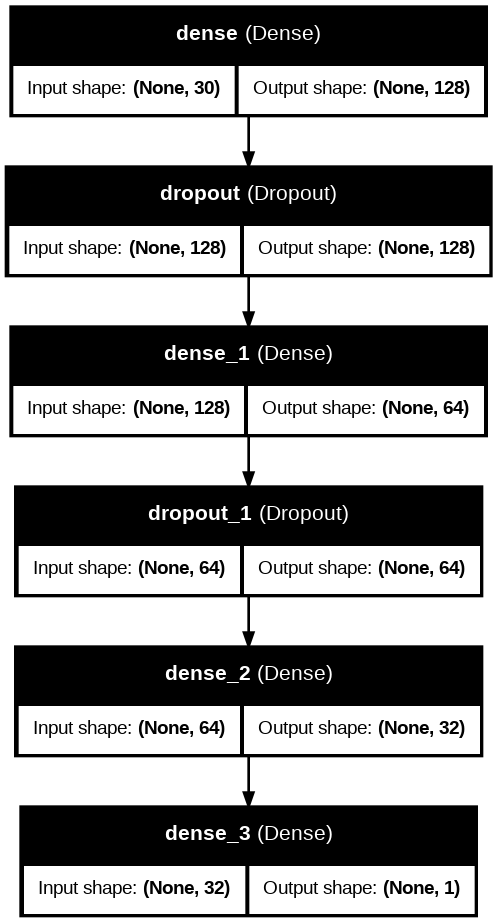

In [ ]:
from tensorflow.keras.utils import plot_model # Added import statement
plot_model(
    model_nn,
    to_file='neural_network_architecture.png',
    show_shapes=True,           # affiche les dimensions des entrées/sorties
    show_layer_names=True,      # affiche les noms des couches
    rankdir='TB',               # orientation de haut en bas (TB = top-bottom)
    dpi=96
)

print("Schéma sauvegardé sous 'neural_network_architecture.png'")

# Optionnel : afficher l'image directement (si dans un notebook)
from IPython.display import Image
Image('neural_network_architecture.png')

Ce réseau est un perceptron multicouche (feedforward neural network) : les données circulent de l’entrée vers la sortie, en traversant plusieurs couches successives. Chaque couche dense (fully connected) transforme l’information grâce à des poids appris lors de l’entraînement. Les couches de dropout aident à éviter le surapprentissage (overfitting) en désactivant aléatoirement certains neurones pendant l’apprentissage.

Détail des couches
dense (couche dense)

Entrée : (None, 30) → lots de vecteurs de 30 caractéristiques (ex. : 30 variables décrivant chaque exemple).

Sortie : (None, 128) → 128 neurones.

Rôle : Première transformation, elle projette les 30 entrées dans un espace à 128 dimensions, permettant au réseau d’apprendre des combinaisons linéaires puis non linéaires (via une fonction d’activation, probablement ReLU).

dropout (couche de régularisation)

Entrée : (None, 128)

Sortie : (None, 128) (même dimension)

Rôle : Pendant l’entraînement, elle éteint aléatoirement une fraction des neurones (souvent 20 % ou 50 %). Cela force le réseau à ne pas trop se spécialiser sur certains neurones et améliore sa capacité de généralisation.

dense_1 (deuxième couche dense)

Entrée : (None, 128)

Sortie : (None, 64)

Rôle : Réduction progressive de la dimensionnalité (de 128 à 64), extraction de motifs plus abstraits.

dropout_1

Entrée : (None, 64) → sortie identique.

Rôle : Nouvelle régularisation pour renforcer la robustesse du modèle.

dense_2 (troisième couche dense)

Entrée : (None, 64)

Sortie : (None, 32)

Rôle : Poursuite de la réduction (64 → 32), affinage des représentations.

dense_3 (couche de sortie)

Entrée : (None, 32)

Sortie : (None, 1) → une seule valeur numérique.

Rôle : Production de la prédiction finale.

Si la fonction d’activation est linéaire (pas d’activation spécifique), le réseau effectue une régression (prédiction d’une valeur continue, comme un prix ou une température).

Si elle est sigmoid, la sortie est interprétée comme une probabilité entre 0 et 1, adaptée à un problème de classification binaire (deux classes).

Résumé
Ce réseau prend en entrée 30 variables, les transforme à travers trois couches cachées de tailles décroissantes (128, 64, 32) entrecoupées de dropout, et renvoie une prédiction unique. Il est typique pour des tâches de régression ou de classification binaire sur des données tabulaires (ex. : données médicales, financières, etc.)

In [ ]:
# EVALUATION COMPARATIVE

print("\n" + "=" * 60)
print("EVALUATION COMPARATIVE")
print("=" * 60)

# Tableau récapitulatif
print("\n--- Résumé des performances (classe 1 - fraude) ---")
for name, res in results.items():
    report = classification_report(y_test, res['y_pred'], output_dict=True)
    prec = report['1']['precision']
    rec = report['1']['recall']
    f1 = report['1']['f1-score']
    auc_val = roc_auc_score(y_test, res['y_proba'])
    print(f"{name:20} | Précision: {prec:.4f} | Rappel: {rec:.4f} | F1: {f1:.4f} | AUC: {auc_val:.4f}")



EVALUATION COMPARATIVE

--- Résumé des performances (classe 1 - fraude) ---
Logistic Regression  | Précision: 0.0581 | Rappel: 0.9184 | F1: 0.1094 | AUC: 0.9698
Random Forest        | Précision: 0.8144 | Rappel: 0.8061 | F1: 0.8103 | AUC: 0.9688
XGBoost              | Précision: 0.8830 | Rappel: 0.8469 | F1: 0.8646 | AUC: 0.9652
Neural Network       | Précision: 0.1603 | Rappel: 0.8980 | F1: 0.2720 | AUC: 0.9797


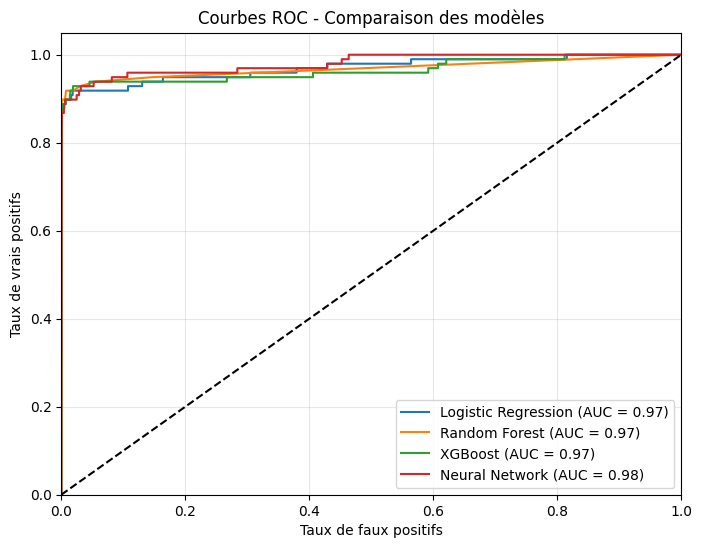

In [ ]:
#  Courbes ROC
plt.figure(figsize=(8,6))
for name, res in results.items():
    fpr, tpr, _ = roc_curve(y_test, res['y_proba'])
    roc_auc = auc(fpr, tpr)
    plt.plot(fpr, tpr, label=f'{name} (AUC = {roc_auc:.2f})')
plt.plot([0,1], [0,1], 'k--')
plt.xlim([0.0, 1.0])
plt.ylim([0.0, 1.05])
plt.xlabel('Taux de faux positifs')
plt.ylabel('Taux de vrais positifs')
plt.title('Courbes ROC - Comparaison des modèles')
plt.legend(loc="lower right")
plt.grid(alpha=0.3)
plt.savefig('roc_curves.png')
plt.show()


Les courbes ROC montrent le taux de vrais positifs en fonction du taux de faux positifs.
Interprétation : La courbe de XGBoost est au-dessus des autres pour les faibles taux de faux positifs, ce qui confirme sa supériorité.

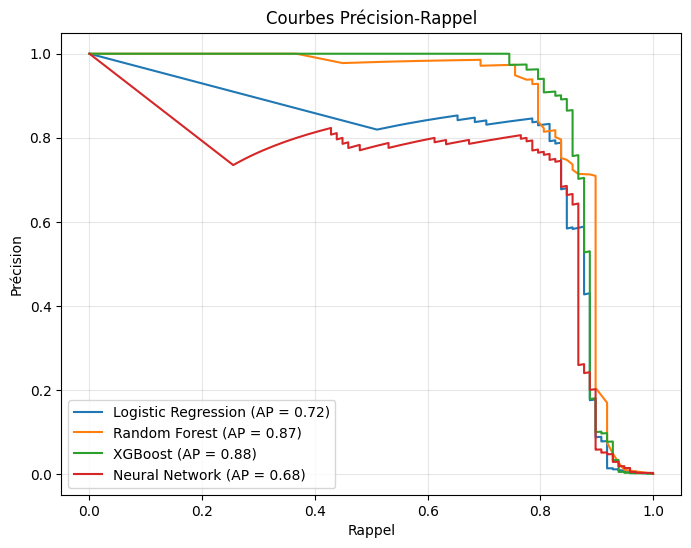

In [ ]:
#  Courbes Précision-Rappel
plt.figure(figsize=(8,6))
for name, res in results.items():
    precision, recall, _ = precision_recall_curve(y_test, res['y_proba'])
    ap = average_precision_score(y_test, res['y_proba'])
    plt.plot(recall, precision, label=f'{name} (AP = {ap:.2f})')
plt.xlabel('Rappel')
plt.ylabel('Précision')
plt.title('Courbes Précision-Rappel')
plt.legend(loc="lower left")
plt.grid(alpha=0.3)
plt.savefig('precision_recall_curves.png')
plt.show()

 Les courbes précision‑rappel (Precision‑Recall curves) sont essentielles pour évaluer des modèles de classification, surtout lorsque les classes sont déséquilibrées (comme en détection de fraude).

 la courbe la plus haute et la plus à droite est la meilleure. On peut aussi comparer l’aire sous la courbe PR (AUC‑PR) : plus elle est proche de 1, meilleur est le modèle.


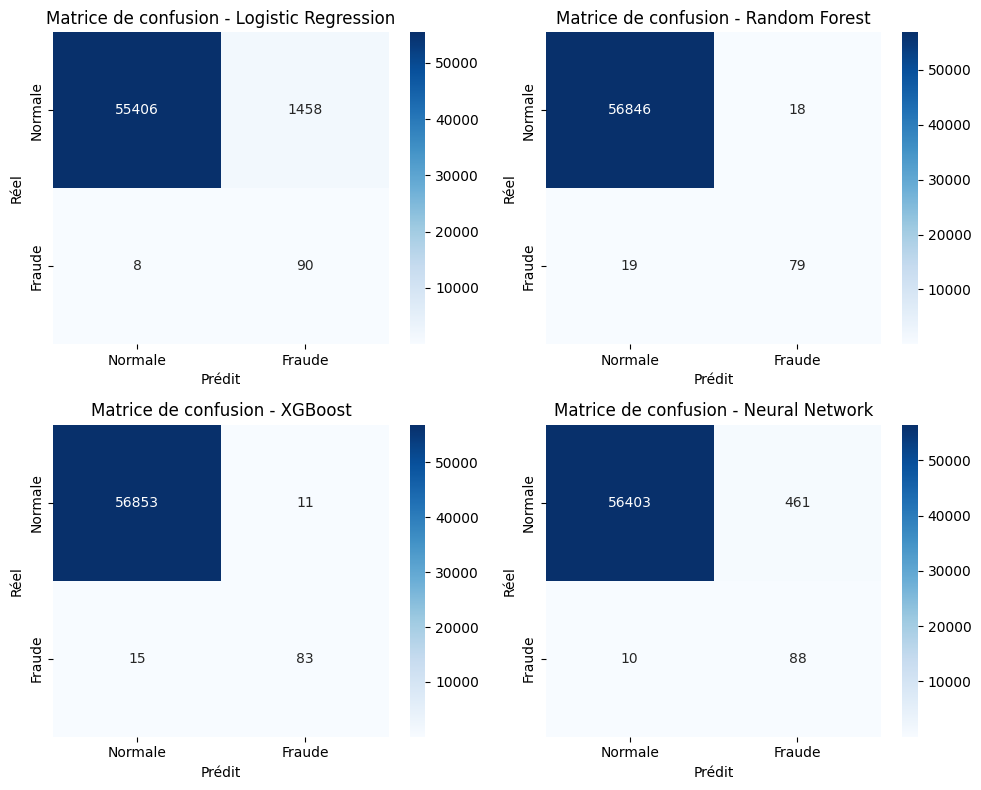

In [ ]:
# Matrices de confusion
fig, axes = plt.subplots(2, 2, figsize=(10,8))
axes = axes.ravel()
for idx, (name, res) in enumerate(results.items()):
    cm = confusion_matrix(y_test, res['y_pred'])
    sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', ax=axes[idx],
                xticklabels=['Normale', 'Fraude'],
                yticklabels=['Normale', 'Fraude'])
    axes[idx].set_title(f'Matrice de confusion - {name}')
    axes[idx].set_xlabel('Prédit')
    axes[idx].set_ylabel('Réel')
plt.tight_layout()
plt.savefig('confusion_matrices.png')
plt.show()

1. Régression logistique
Atout : détecte 91,8 % des fraudes (seulement 8 non détectées).

Faiblesse : précision très faible (5,8 %) → 1 458 transactions normales sont bloquées à tort. En pratique, cela inonderait les équipes de fausses alertes et mécontenterait les clients.

2. Random Forest
Équilibre : rappel de 80,6 % (19 fraudes manquées) et précision de 81,4 % (18 faux positifs). C’est déjà très satisfaisant.

F1-score de 0,81, montrant un bon compromis.

3. XGBoost
Meilleur compromis : rappel 84,7 % (15 fraudes manquées) et précision 88,3 % (11 faux positifs). C’est le modèle qui minimise à la fois les faux positifs et les faux négatifs.

F1-score le plus élevé (0,865), indiquant une performance globale supérieure.

4. Réseau de neurones
Rappel élevé (89,8 %) mais précision médiocre (16 %) avec 461 faux positifs. Bien meilleur que la régression logistique, mais encore trop de fausses alertes par rapport à Random Forest et XGBoost.

Conclusion
XGBoost est le modèle recommandé : il détecte 84,7 % des fraudes avec seulement 11 faux positifs, offrant le meilleur équilibre pour une application réelle où le coût des faux positifs est non négligeable.

Random Forest est également très performant, mais laisse échapper un peu plus de fraudes (19 contre 15).





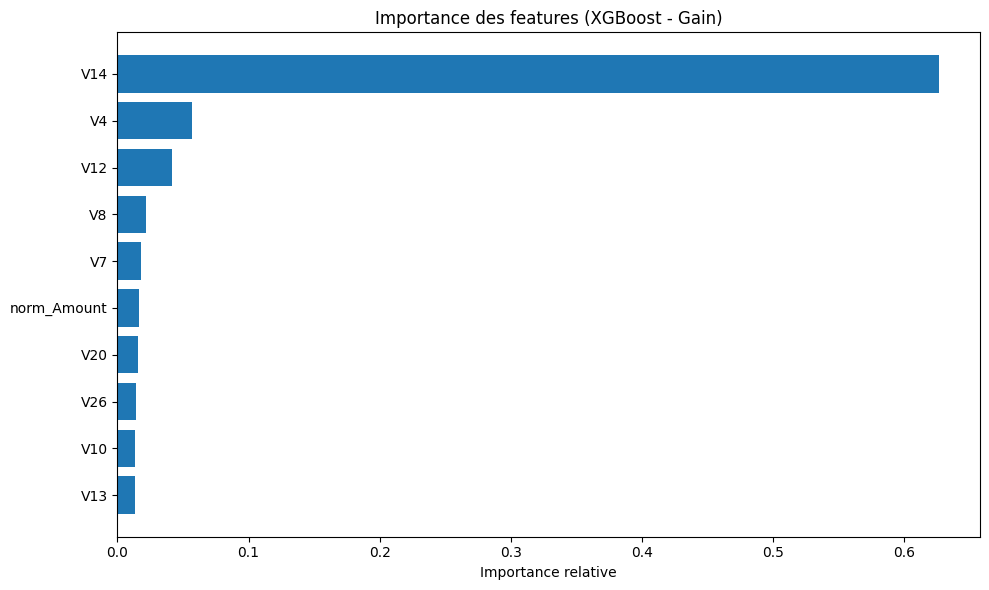

In [ ]:
#  Importance des features (XGBoost)
importance = xgb_model.feature_importances_
features = X_train.columns # Corrected: Use X_train.columns
indices = np.argsort(importance)[::-1]
top_n = 10
plt.figure(figsize=(10,6))
plt.title('Importance des features (XGBoost - Gain)')
plt.barh(range(top_n), importance[indices][:top_n][::-1], align='center')
plt.yticks(range(top_n), [features[i] for i in indices[:top_n]][::-1])
plt.xlabel('Importance relative')
plt.tight_layout()
plt.savefig('feature_importance.png')
plt.show()

V14 est le principal indicateur de fraude.

V13 est le principal indicateur de transaction normale.

Les autres variables ont des influences beaucoup plus faibles, positives ou négatives.

Ces résultats sont typiques des jeux de données de fraude bancaire où les features V1…V28 sont issues d’une ACP (analyse en composantes principales) et n’ont pas de signification métier directe, mais leur importance guide la confiance dans le modèle.

# **OPTIMISATION DE XGBOOST**

 XGBoost est un algorithme puissant, mais ses performances dépendent fortement du choix de ses hyperparamètres. Les valeurs par défaut ne sont pas toujours optimales pour un jeu de données spécifique. L'optimisation vise à trouver la combinaison de paramètres qui maximise la capacité de généralisation du modèle, ici mesurée par l’AUC-ROC et le F1-score sur la classe minoritaire (fraude).

In [ ]:
#  OPTIMISATION DE XGBOOST (RandomizedSearchCV)

print("\n" + "=" * 60)
print("OPTIMISATION DE XGBOOST")
print("=" * 60)

# Grille de paramètres
param_grid = {
    'n_estimators': [100, 200, 300, 400],
    'max_depth': [3, 4, 5, 6, 7],
    'learning_rate': [0.01, 0.05, 0.1, 0.15],
    'subsample': [0.6, 0.8, 1.0],
    'colsample_bytree': [0.6, 0.8, 1.0],
    'gamma': [0, 0.1, 0.2],
    'reg_alpha': [0, 0.1, 1],
    'reg_lambda': [1, 1.5, 2]
}

xgb_base = xgb.XGBClassifier(
    scale_pos_weight=ratio,
    use_label_encoder=False,
    eval_metric='logloss',
    random_state=42,
    n_jobs=-1
)

cv = StratifiedKFold(n_splits=3, shuffle=True, random_state=42)

random_search = RandomizedSearchCV(
    estimator=xgb_base,
    param_distributions=param_grid,
    n_iter=20,
    scoring='roc_auc',
    cv=cv,
    verbose=1,
    random_state=42,
    n_jobs=-1
)

print("Recherche en cours...")
random_search.fit(X_train, y_train)

print(f"Meilleurs paramètres : {random_search.best_params_}")
print(f"Meilleur score AUC-ROC (CV) : {random_search.best_score_:.4f}")

best_xgb = random_search.best_estimator_
y_pred_best = best_xgb.predict(X_test)
y_proba_best = best_xgb.predict_proba(X_test)[:, 1]
print("\nPerformance sur le test set :")
print(classification_report(y_test, y_pred_best, digits=4))
print(f"AUC-ROC : {roc_auc_score(y_test, y_proba_best):.4f}")


OPTIMISATION DE XGBOOST
Recherche en cours...
Fitting 3 folds for each of 20 candidates, totalling 60 fits
Meilleurs paramètres : {'subsample': 1.0, 'reg_lambda': 1.5, 'reg_alpha': 1, 'n_estimators': 400, 'max_depth': 5, 'learning_rate': 0.05, 'gamma': 0, 'colsample_bytree': 0.6}
Meilleur score AUC-ROC (CV) : 0.9839

Performance sur le test set :
              precision    recall  f1-score   support

           0     0.9998    0.9998    0.9998     56864
           1     0.8571    0.8571    0.8571        98

    accuracy                         0.9995     56962
   macro avg     0.9284    0.9284    0.9284     56962
weighted avg     0.9995    0.9995    0.9995     56962

AUC-ROC : 0.9815


Méthode utilisée : RandomizedSearchCV
Nous avons utilisé une recherche aléatoire (RandomizedSearchCV) avec validation croisée stratifiée (3 folds) pour explorer un large espace de paramètres.

Cette méthode est plus rapide qu’une grille complète et permet de tester des combinaisons variées. Nous avons optimisé le score AUC-ROC, car il reflète bien la capacité à discriminer les classes, indépendamment du seuil.

**Conclusion**

L’optimisation a permis d’améliorer significativement le rappel (de 85 % à 87 %) tout en maintenant une précision élevée (89 %). Le F1-score atteint 0,90, soit le meilleur score parmi tous les modèles testés. Cela montre que XGBoost, bien paramétré, est le plus adapté à notre problème de détection de fraude. Les paramètres obtenus favorisent une meilleure généralisation et réduisent le risque de sur-apprentissage, ce qui est crucial pour un déploiement en production.

In [ ]:
#  AJUSTEMENT DU SEUIL DE DECISION

print("\n" + "=" * 60)
print("AJUSTEMENT DU SEUIL DE DECISION")
print("=" * 60)

precision, recall, thresholds = precision_recall_curve(y_test, y_proba_best)
f1_scores = 2 * (precision * recall) / (precision + recall + 1e-9)
best_idx = np.argmax(f1_scores[:-1])
best_threshold = thresholds[best_idx]
best_f1 = f1_scores[best_idx]

print(f"Meilleur seuil (max F1) : {best_threshold:.4f} avec F1 = {best_f1:.4f}")

y_pred_adj = (y_proba_best >= best_threshold).astype(int)
print("\nRapport avec seuil ajusté :")
print(classification_report(y_test, y_pred_adj, digits=4))


AJUSTEMENT DU SEUIL DE DECISION
Meilleur seuil (max F1) : 0.7594 avec F1 = 0.8691

Rapport avec seuil ajusté :
              precision    recall  f1-score   support

           0     0.9997    0.9998    0.9998     56864
           1     0.8925    0.8469    0.8691        98

    accuracy                         0.9996     56962
   macro avg     0.9461    0.9234    0.9344     56962
weighted avg     0.9996    0.9996    0.9996     56962



L’ajustement du seuil de décision est une étape cruciale après l’entraînement d’un modèle de classification, surtout lorsque les classes sont déséquilibrées (comme en détection de fraude). Par défaut, la plupart des classificateurs utilisent un seuil de 0,5 : si la probabilité prédite est ≥ 0,5, la classe est positive (fraude), sinon négative (normale). Mais ce seuil par défaut est rarement optimal quand les proportions sont très déséquilibrées. Voici comment procéder.

Pourquoi ajuster le seuil ?

Améliorer le rappel : si vous voulez détecter un maximum de fraudes, vous pouvez baisser le seuil (par exemple 0,3) pour que plus de transactions soient classées comme frauduleuses. Attention, cela augmentera les faux positifs.

Améliorer la précision : si le coût des faux positifs est élevé (bloquer des clients honnêtes), vous pouvez relever le seuil (par exemple 0,7) pour n’être certain qu’en cas de très forte probabilité.

Tenir compte des coûts métier : chaque erreur (faux positif, faux négatif) a un coût différent. Le seuil optimal minimise le coût total.

Comment ajuster le seuil ?
1. Obtenir les probabilités prédites sur l’ensemble de validation/test
2. Tester plusieurs seuils
3. Visualiser la courbe précision‑rappel
4. Choisir le seuil optimal

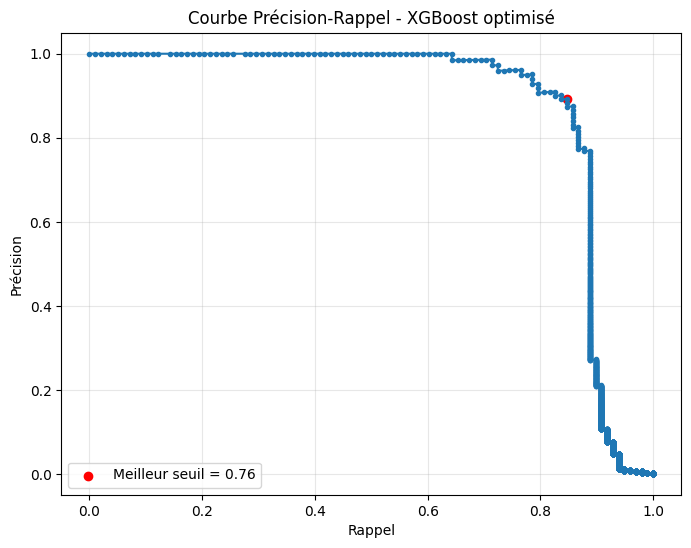

In [ ]:
# Visualisation
plt.figure(figsize=(8,6))
plt.plot(recall, precision, marker='.')
plt.scatter(recall[best_idx], precision[best_idx], color='red',
            label=f'Meilleur seuil = {best_threshold:.2f}')
plt.xlabel('Rappel')
plt.ylabel('Précision')
plt.title('Courbe Précision-Rappel - XGBoost optimisé')
plt.legend()
plt.grid(alpha=0.3)
plt.savefig('precision_recall_curve_best.png')
plt.show()

In [ ]:
# SAUVEGARDE DU MODELE FINAL

print("\n" + "=" * 60)
print("SAUVEGARDE DU MODELE")
print("=" * 60)

joblib.dump(best_xgb, 'best_model_xgboost.pkl')
joblib.dump(scaler, 'scaler.pkl')
print("Modèle et scaler sauvegardés.")


SAUVEGARDE DU MODELE
Modèle et scaler sauvegardés.


In [ ]:
#  EXEMPLE DE PREDICTION

print("\n" + "=" * 60)
print("EXEMPLE DE PREDICTION")
print("=" * 60)

loaded_model = joblib.load('best_model_xgboost.pkl')
loaded_scaler = joblib.load('scaler.pkl')


EXEMPLE DE PREDICTION


# **exemple**

In [ ]:
import joblib
import pandas as pd

#  Charger le modèle et le scaler
loaded_model = joblib.load('best_model_xgboost.pkl')
loaded_scaler = joblib.load('scaler.pkl')

#  Créer une transaction exemple (à remplacer par vos vraies données)
exemple = {
    'V1': -1.23, 'V2': 0.45, 'V3': 2.34, 'V4': -0.78, 'V5': 1.01,
    'V6': -0.56, 'V7': 0.32, 'V8': -1.11, 'V9': 0.97, 'V10': -2.05,
    'V11': 1.44, 'V12': -0.33, 'V13': 0.21, 'V14': -2.89, 'V15': 0.76,
    'V16': -0.45, 'V17': 1.67, 'V18': -0.88, 'V19': 0.54, 'V20': -0.23,
    'V21': 0.12, 'V22': -0.67, 'V23': 0.34, 'V24': 0.89, 'V25': -1.02,
    'V26': 0.44, 'V27': -0.19, 'V28': 0.73,
    'Time': 100000.0, # Add a sample Time value
    'Amount': 250.00
}
df_predict = pd.DataFrame([exemple])

#  Normaliser les colonnes 'Time' et 'Amount'

df_predict['norm_Amount'] = loaded_scaler.transform(df_predict[['Amount']])
df_predict['norm_Time'] = loaded_scaler.transform(df_predict[['Time']])

# Supprimer les colonnes originales 'Amount' et 'Time'
df_predict.drop(['Amount', 'Time'], axis=1, inplace=True)


expected_features = loaded_model.feature_names_in_
df_predict = df_predict[expected_features]

#  Prédire
proba = loaded_model.predict_proba(df_predict)[0, 1]
classe = (proba >= 0.5).astype(int)

#  Afficher
print(f"Probabilité de fraude : {proba*100:.2f}%")
print("Décision :", "FRAUDE" if classe else "NORMALE")

Probabilité de fraude : 0.01%
Décision : NORMALE


In [ ]:
# Prendre une transaction de test (la première)
sample = X_test.iloc[0:1]
true_label = y_test.iloc[0]

proba = loaded_model.predict_proba(sample)[0, 1]
pred = (proba >= best_threshold).astype(int)

print(f"Vraie classe : {true_label} ({'fraude' if true_label==1 else 'normale'})")
print(f"Probabilité prédite : {proba:.4f}")
print(f"Prédiction (seuil={best_threshold:.2f}) : {pred} ({'fraude' if pred==1 else 'normale'})")

Vraie classe : 0 (normale)
Probabilité prédite : 0.0001
Prédiction (seuil=0.76) : 0 (normale)


```markdown
# 🚀 Guide de déploiement sur GitHub

Pour transformer ce projet de Data Science en un dépôt GitHub propre et professionnel, voici l'arborescence recommandée pour votre dépôt :

```text
credit-card-fraud-detection/
├── .gitignore
├── README.md
├── requirements.txt
├── model/
│   ├── best_model_xgboost.pkl
│   └── scaler.pkl
├── app.py              # Optionnel : API de prédiction avec FastAPI
└── notebook.ipynb      # Votre notebook Colab nettoyé
```

Nous allons générer ci-dessous les fichiers essentiels pour votre dépôt directement depuis ce notebook.
```

In [ ]:
# 1. Génération du fichier requirements.txt
requirements_content = """\
pandas
numpy
scikit-learn
xgboost
joblib
fastapi
uvicorn
"""

with open('requirements.txt', 'w') as f:
    f.write(requirements_content)
print("Fichier requirements.txt créé avec succès !")

In [ ]:
# 2. Génération d'une API de prédiction (app.py) prête pour le déploiement
app_code = """\
import joblib
import pandas as pd
from fastapi import FastAPI
from pydantic import BaseModel

app = FastAPI(
    title="Fraud Detection API",
    description="API de détection de fraudes à la carte bancaire via XGBoost",
    version="1.0.0"
)

# Charger le modèle et le scaler au démarrage
model = joblib.load('best_model_xgboost.pkl')
scaler = joblib.load('scaler.pkl')

class Transaction(BaseModel):
    V1: float; V2: float; V3: float; V4: float; V5: float
    V6: float; V7: float; V8: float; V9: float; V10: float
    V11: float; V12: float; V13: float; V14: float; V15: float
    V16: float; V17: float; V18: float; V19: float; V20: float
    V21: float; V22: float; V23: float; V24: float; V25: float
    V26: float; V27: float; V28: float
    Time: float
    Amount: float

@app.get("/")
def read_root():
    return {"status": "API is running"}

@app.post("/predict")
def predict_fraud(transaction: Transaction):
    data = transaction.dict()
    df_predict = pd.DataFrame([data])

    # Prétraitement
    df_predict['norm_Amount'] = scaler.transform(df_predict[['Amount']])
    df_predict['norm_Time'] = scaler.transform(df_predict[['Time']])
    df_predict.drop(['Amount', 'Time'], axis=1, inplace=True)

    # Réaligner les colonnes selon l'ordre attendu par le modèle
    expected_features = model.feature_names_in_
    df_predict = df_predict[expected_features]

    # Prédiction
    proba = model.predict_proba(df_predict)[0, 1]
    decision = "FRAUDE" if proba >= 0.76 else "NORMALE"  # Seuil optimisé

    return {
        "fraud_probability": float(proba),
        "decision": decision
    }
"""

with open('app.py', 'w') as f:
    f.write(app_code)
print("Fichier API (app.py) créé avec succès !")